# V3: Monocular Video → Geometric VO + Sparse Mapping + GPU AI Depth + Plotly 3D

**Kaggle GPU notebook — nâng cấp từ video RGB notebook.** Thiết kế dùng **2-view geometry để khởi tạo**, sau đó **2D–3D PnP tracking + triangulation trên keyframe**; giữ depth network như bản đồ minh họa riêng. Không dùng ground truth để tracking. Monocular không khôi phục được metric scale từ video đơn thuần.

**Giới hạn:** đây là *sparse-mapping visual odometry prototype*, chưa phải SLAM đầy đủ: chưa có global loop-closure/pose-graph optimization hoặc local bundle adjustment hoàn chỉnh. Không trình bày số point cloud là thước đo độ chính xác.


**Additional views:** RGB + predicted relative depth, colored 3D single frame, and optional sensor-depth reference from timestamp-matched TUM RGB-D.

**New:** Section 9 supplies an independent, sensor-assisted RGB-D tracking baseline for TUM (metric depth), same-frame depth comparison, and timestamp-aligned trajectory evaluation. The original MP4 monocular experiment remains unchanged; RGB-D results must not be represented as monocular results.

**V2 improvements:** direct timestamped TUM RGB loading (`INPUT_MODE`), FRAME_STEP=1, optical-flow 3D landmark propagation, map-PnP fallback and tracking diagnostics. Previous RGB-D baseline + depth sections preserved. This is a research prototype, not validated full SLAM.


**V3:** Optical flow + keyframe-local landmark matching + keyframe relocalization + geometric validation. Preserve RGB-D and AI Depth baseline.


## 1. Cài đặt & cấu hình Kaggle

In [53]:
%pip -q install "transformers>=4.44,<5" "accelerate>=0.30" "plyfile>=1.0" "plotly>=5.20" "scipy>=1.11"

Note: you may need to restart the kernel to use updated packages.


In [54]:
import os
from pathlib import Path

DATA_DIR = Path("/kaggle/working/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

URL = (
    "https://cvg.cit.tum.de/rgbd/dataset/freiburg1/"
    "rgbd_dataset_freiburg1_room.tgz"
)

ARCHIVE = DATA_DIR / "rgbd_dataset_freiburg1_room.tgz"

# Tải dataset
!wget -c "{URL}" -O "{ARCHIVE}"

# Giải nén
!tar -xzf "{ARCHIVE}" -C "{DATA_DIR}"

DATASET_PATH = DATA_DIR / "rgbd_dataset_freiburg1_room"

print("Dataset:", DATASET_PATH)
print("RGB images:", len(list((DATASET_PATH / "rgb").glob("*.png"))))
print("Depth images:", len(list((DATASET_PATH / "depth").glob("*.png"))))

--2026-10-11 19:10:40--  https://cvg.cit.tum.de/rgbd/dataset/freiburg1/rgbd_dataset_freiburg1_room.tgz
Resolving cvg.cit.tum.de (cvg.cit.tum.de)... 131.159.19.110, 2a09:80c0:18::1110
Connecting to cvg.cit.tum.de (cvg.cit.tum.de)|131.159.19.110|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://webshare.cvg.cit.tum.de/g/rgbd/dataset/freiburg1/rgbd_dataset_freiburg1_room.tgz [following]
--2026-10-11 19:10:41--  https://webshare.cvg.cit.tum.de/g/rgbd/dataset/freiburg1/rgbd_dataset_freiburg1_room.tgz
Resolving webshare.cvg.cit.tum.de (webshare.cvg.cit.tum.de)... 131.159.19.221, 2a09:80c0:18::1221
Connecting to webshare.cvg.cit.tum.de (webshare.cvg.cit.tum.de)|131.159.19.221|:443... connected.
HTTP request sent, awaiting response... 416 Requested Range Not Satisfiable

    The file is already fully retrieved; nothing to do.

Dataset: /kaggle/working/data/rgbd_dataset_freiburg1_room
RGB images: 1362
Depth images: 1360


In [55]:
print("RGB:", len(list((DATASET_PATH / "rgb").glob("*.png"))))
print("Depth:", len(list((DATASET_PATH / "depth").glob("*.png"))))

print("RGB metadata:", (DATASET_PATH / "rgb.txt").exists())
print("Ground truth:", (DATASET_PATH / "groundtruth.txt").exists())

RGB: 1362
Depth: 1360
RGB metadata: True
Ground truth: True


In [56]:
import cv2

rgb_files = sorted((DATASET_PATH / "rgb").glob("*.png"))

first = cv2.imread(str(rgb_files[0]))
h, w = first.shape[:2]

output_path = "/kaggle/working/room.mp4"

writer = cv2.VideoWriter(
    output_path,
    cv2.VideoWriter_fourcc(*"mp4v"),
    30,
    (w, h)
)

for file in rgb_files:
    frame = cv2.imread(str(file))
    writer.write(frame)

writer.release()
print("Video saved:", output_path)

Video saved: /kaggle/working/room.mp4


In [57]:
from pathlib import Path
import csv, json, math, gc
import numpy as np, cv2, torch
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from PIL import Image
from plyfile import PlyData, PlyElement
from scipy.spatial import cKDTree
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

# Chỉnh file MP4 tại đây. Có thể dùng video có sẵn trong /kaggle/input/.
VIDEO_PATH = "/kaggle/working/room.mp4"
OUTPUT_DIR = Path('/kaggle/working/visual_slam_upgrade'); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
INPUT_MODE='tum_rgb'  # 'tum_rgb' (recommended TUM) or 'video' (generic MP4)
MAX_SOURCE_FRAMES=2000; FRAME_STEP=1; RESIZE_WIDTH=640
ORB_FEATURES=3500; MIN_INIT_INLIERS=55; MIN_PNP_INLIERS=20
MIN_TRIANGULATION_ANGLE_DEG=0.8; KEYFRAME_INTERVAL=8
MAX_MAP_POINTS=35000; MAX_TRACK_FRAME_GAP=5
DEPTH_MODEL='depth-anything/Depth-Anything-V2-Small-hf'
DEPTH_FRAMES=18; PIXEL_STRIDE=7; DENSE_MAX_POINTS=100000
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
SEED=42; rng=np.random.default_rng(SEED)

# TUM Freiburg1 RGB factory intrinsics for original 640x480 images. This is calibrated approximation
# for TUM fr1 video made from its *unaltered* RGB images. Do not use for unrelated mobile video.
CAMERA_PROFILE='tum_fr1'  # 'tum_fr1', 'custom' or 'approx'
K_CUSTOM=None             # 3x3 intrinsic matrix for ORIGINAL video resolution
DIST_CUSTOM=None          # distortion coefficients when available
print('device:',DEVICE)

device: cuda


## 2. Video → frame và camera intrinsics

K phụ thuộc camera **và kích thước ảnh**. TUM `fr1` sử dụng calibration riêng; đối với video điện thoại cần nhập `K_CUSTOM` đo/calibrate trước. Với `CAMERA_PROFILE='approx'`, chỉ xem kết quả là minh họa, không đo metric.

Input: tum_rgb frames: 1362 size: 640 480 FPS: 31.160322130100145 K: [[517.3   0.  318.6]
 [  0.  516.5 255.3]
 [  0.    0.    1. ]]


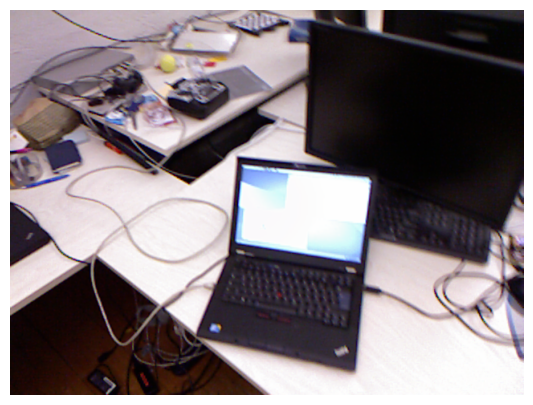

In [58]:

# Load original timestamped TUM images, or generic MP4 frames.
def read_tum_index(path):
    out=[]
    with open(path,encoding='utf-8') as f:
        for line in f:
            row=line.strip().split()
            if len(row)>=2 and not row[0].startswith('#'):
                out.append((float(row[0]),row[1]))
    return out

frames=[];source_size=None; fps=float('nan')
if INPUT_MODE=='tum_rgb':
    rgb_entries=read_tum_index(DATASET_PATH/'rgb.txt')
    for idx,(ts,rel) in enumerate(rgb_entries[:MAX_SOURCE_FRAMES]):
        if idx%FRAME_STEP: continue
        bgr=cv2.imread(str(DATASET_PATH/rel),cv2.IMREAD_COLOR)
        if bgr is None: continue
        if source_size is None: source_size=(bgr.shape[1],bgr.shape[0])
        hh,ww=bgr.shape[:2]
        if ww>RESIZE_WIDTH:
            nw=RESIZE_WIDTH;nh=int(round(hh*nw/ww));bgr=cv2.resize(bgr,(nw,nh),interpolation=cv2.INTER_AREA)
        rgb=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
        frames.append(dict(rgb=rgb,gray=cv2.cvtColor(bgr,cv2.COLOR_BGR2GRAY),source_idx=idx,time=ts))
    fps=1.0/np.median(np.diff([x[0] for x in rgb_entries])) if len(rgb_entries)>2 else float('nan')
else:
    cap=cv2.VideoCapture(str(VIDEO_PATH));assert cap.isOpened(),f'Cannot open {VIDEO_PATH}'
    fps=float(cap.get(cv2.CAP_PROP_FPS));idx=0
    while idx<MAX_SOURCE_FRAMES:
        ret,bgr=cap.read()
        if not ret:break
        if source_size is None:source_size=(bgr.shape[1],bgr.shape[0])
        if idx%FRAME_STEP==0:
            hh,ww=bgr.shape[:2]
            if ww>RESIZE_WIDTH:
                nw=RESIZE_WIDTH;nh=int(round(hh*nw/ww));bgr=cv2.resize(bgr,(nw,nh),interpolation=cv2.INTER_AREA)
            rgb=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
            frames.append(dict(rgb=rgb,gray=cv2.cvtColor(bgr,cv2.COLOR_BGR2GRAY),source_idx=idx,time=idx/fps if fps>0 else None))
        idx+=1
    cap.release()
assert len(frames)>2,'Need at least 3 frames'
h,w=frames[0]['gray'].shape;orig_w,orig_h=source_size
if CAMERA_PROFILE=='tum_fr1':
    if source_size!=(640,480): print('WARNING: TUM fr1 intrinsics expect original 640x480 images')
    K0=np.array([[517.3,0,318.6],[0,516.5,255.3],[0,0,1.]],float)
    dist=np.array([0.2624,-0.9531,-0.0054,0.0026,1.1633],float)
elif CAMERA_PROFILE=='custom':
    assert K_CUSTOM is not None
    K0=np.asarray(K_CUSTOM,float)
    dist=np.zeros(5) if DIST_CUSTOM is None else np.asarray(DIST_CUSTOM,float)
else:
    K0=np.array([[.9*orig_w,0,(orig_w-1)/2],[0,.9*orig_w,(orig_h-1)/2],[0,0,1]],float)
    dist=np.zeros(5);print('WARNING: approximate intrinsics, trajectory cannot be accurately evaluated')
K=K0.copy();K[0,:]*=w/orig_w;K[1,:]*=h/orig_h
# Keep the TUM RGB/D images as provided; do not undistort registered RGB-D without consistent calibration.
UNDISTORT_INPUT=False
if UNDISTORT_INPUT:
    if INPUT_MODE=='tum_rgb':raise ValueError('TUM RGB-D: undistort requires consistent RGB/depth calibration and registration')
    for fr in frames:
        fr['rgb']=cv2.undistort(fr['rgb'],K,dist)
        fr['gray']=cv2.cvtColor(fr['rgb'],cv2.COLOR_RGB2GRAY)
print('Input:',INPUT_MODE,'frames:',len(frames),'size:',w,h,'FPS:',fps,'K:',K)
plt.figure(figsize=(8,5));plt.imshow(frames[0]['rgb']);plt.axis('off');plt.show()


## 3. ORB, matching, 2-view geometry và initialization

In [59]:
orb=cv2.ORB_create(nfeatures=ORB_FEATURES)
matcher=cv2.BFMatcher(cv2.NORM_HAMMING)
for f in frames:
    f['kp'],f['desc']=orb.detectAndCompute(f['gray'],None)
    f['xy']=np.float64([p.pt for p in f['kp']]).reshape(-1,2)

def match_idx(fa,fb,ratio=0.72):
    da,db=fa['desc'],fb['desc']
    if da is None or db is None or len(da)<2 or len(db)<2: return []
    pairs=matcher.knnMatch(da,db,k=2)
    good=[m for row in pairs if len(row)==2 for m,n in [row] if m.distance<ratio*n.distance]
    return sorted(good,key=lambda x:x.distance)

def transform(R,t):
    M=np.eye(4,dtype=float);M[:3,:3]=R;M[:3,3]=np.asarray(t).ravel();return M

def cam_projection(Twc):
    # Tcw = inverse world→camera (Twc stores camera→world)
    Tcw=np.linalg.inv(Twc)
    return K@Tcw[:3,:]

def triangulate(Twa,Twb,uv_a,uv_b):
    xyz4=cv2.triangulatePoints(cam_projection(Twa),cam_projection(Twb),uv_a.T,uv_b.T)
    valid=np.abs(xyz4[3])>1e-10
    xyz=np.zeros((len(uv_a),3),dtype=np.float64)
    xyz[valid]=(xyz4[:3,valid]/xyz4[3,valid]).T
    Tca=np.linalg.inv(Twa); Tcb=np.linalg.inv(Twb)
    za=(xyz@Tca[:3,:3].T+Tca[:3,3])[:,2]
    zb=(xyz@Tcb[:3,:3].T+Tcb[:3,3])[:,2]
    valid &= np.isfinite(xyz).all(axis=1)&(za>0)&(zb>0)
    def reproject(Twc,X):
        P=cam_projection(Twc);q=(P[:,:3]@X.T+P[:,3:4]).T
        return q[:,:2]/np.clip(q[:,2:3],1e-12,None)
    err=np.linalg.norm(reproject(Twa,xyz)-uv_a,axis=1)+np.linalg.norm(reproject(Twb,xyz)-uv_b,axis=1)
    va=xyz-Twa[:3,3]; vb=xyz-Twb[:3,3]
    cosine=np.sum(va*vb,axis=1)/np.maximum(np.linalg.norm(va,axis=1)*np.linalg.norm(vb,axis=1),1e-12)
    angle=np.rad2deg(np.arccos(np.clip(cosine,-1,1)))
    valid&=(err<6)&(angle>MIN_TRIANGULATION_ANGLE_DEG)
    return xyz,valid

# Initialize when baseline/parallax is adequate; do not force a unit translation every frame.
init=None
for j in range(1,min(40,len(frames))):
    ms=match_idx(frames[0],frames[j]);
    if len(ms)<MIN_INIT_INLIERS:continue
    a=np.float64([frames[0]['xy'][m.queryIdx] for m in ms]);z=np.float64([frames[j]['xy'][m.trainIdx] for m in ms])
    E,mask=cv2.findEssentialMat(a,z,K,method=cv2.RANSAC,prob=0.999,threshold=1.5)
    if E is None:continue
    nin,R,t,posemask=cv2.recoverPose(E[:3,:3],a,z,K,mask=mask)
    if nin<MIN_INIT_INLIERS:continue
    good=posemask.ravel()>0
    if np.median(np.linalg.norm(z[good]-a[good],axis=1))<3:continue
    T0=np.eye(4);Tj=np.linalg.inv(transform(R,t))  # baseline normalized to one arbitrary unit
    X,valid=triangulate(T0,Tj,a[good],z[good]);
    if valid.sum()<35:continue
    init=(j,ms,good,X,valid,Tj); break
assert init is not None,'Initialization failed; try a more textured video with parallax or decrease FRAME_STEP'
j,ms,good,X,valid,Tj=init
print('Initialized using frames 0 and',j,'| valid triangulated points:',valid.sum())

Initialized using frames 0 and 3 | valid triangulated points: 807


## 4. V3 — Monocular Tracking: optical flow → local map → keyframe relocalization

V3 giữ **3D landmarks + ORB descriptors** trong world coordinate, liên kết landmark với keyframe để tìm lại pose khi LK optical flow mất track. PnP và reprojection filtering sử dụng RGB và calibration, **không dùng depth sensor hoặc ground truth**. Mỗi frame sẽ được đánh dấu `flow`, `local`, `local_ungated`, `relocalize`, hoặc `lost` để đo hiệu quả. Phiên bản này chưa có loop closure hay bundle adjustment. Kết quả cần đánh giá lại trên Kaggle.

In [60]:
# V3: track 3D landmarks through LK flow, try projection-gated local PnP,
# then relocalize using a database of keyframe-linked 3D landmarks.
# Monocular: NO TUM sensor depth / ground truth is used in tracking.
from collections import Counter

V3_MIN_INLIER_RATIO = 0.32
V3_MAX_MEDIAN_REPROJ_PX = 3.0
V3_LOCAL_SEARCH_RADIUS_PX = 28
V3_LOCAL_MAX_CANDIDATES = 3500
V3_RELOCALIZATION_TOP_K = 6
V3_KF_MIN_ADDED = 12
V3_KF_MIN_PARALLAX_PX = 8.0

map_xyz=[];map_desc=[];map_rgb=[];keyframes=[]
poses=[None]*len(frames);poses[0]=np.eye(4);poses[j]=Tj
track_log=[{'frame':i,'status':'init' if i in (0,j) else 'not_estimated','matches':0,'inliers':0} for i in range(len(frames))]

good_matches=[m for m,k in zip(ms,good) if k]
valid_matches=[m for m,k in zip(good_matches,valid) if k]
for m,x,keep in zip(good_matches,X,valid):
    if keep:
        map_xyz.append(x)
        map_desc.append(frames[0]['desc'][m.queryIdx])
        xy=frames[0]['xy'][m.queryIdx]
        u=int(np.clip(round(xy[0]),0,w-1));v=int(np.clip(round(xy[1]),0,h-1))
        map_rgb.append(frames[0]['rgb'][v,u])
map_xyz=np.asarray(map_xyz,dtype=np.float64)
map_desc=np.asarray(map_desc,dtype=np.uint8)
map_rgb=np.asarray(map_rgb,dtype=np.uint8)
keyframes=[0,j]
# Every keyframe database entry only stores descriptors tied to VALID 3D landmarks.
kf_db=[]

def build_keyframe_entry(frame_id, ids):
    ids=np.unique(np.asarray(ids,dtype=np.int32))
    ids=ids[(ids>=0)&(ids<len(map_xyz))]
    if len(ids)<MIN_PNP_INLIERS: return False
    kf_db.append({'frame':frame_id,'ids':ids.copy(),
                  'desc':np.ascontiguousarray(map_desc[ids].copy())})
    return True

build_keyframe_entry(0,np.arange(len(map_xyz)))
build_keyframe_entry(j,np.arange(len(map_xyz)))


def unique_ratio_matches(query_desc, train_desc, ratio=0.79):
    if query_desc is None or train_desc is None or len(query_desc)<2 or len(train_desc)<2:
        return []
    pairs=matcher.knnMatch(query_desc,train_desc,k=2)
    cand=[m for row in pairs if len(row)==2 for m,n in [row] if m.distance<ratio*n.distance]
    used_q=set();used_t=set();out=[]
    for m in sorted(cand,key=lambda t:t.distance):
        if m.queryIdx in used_q or m.trainIdx in used_t:continue
        used_q.add(m.queryIdx);used_t.add(m.trainIdx);out.append(m)
    return out


def estimate_pose(obj,pix):
    if len(obj)<max(6,MIN_PNP_INLIERS):
        return None,0,np.array([],int),None,'too_few_correspondences'
    obj=np.ascontiguousarray(obj,dtype=np.float64)
    pix=np.ascontiguousarray(pix,dtype=np.float64)
    try:
        ok,rvec,tvec,inliers=cv2.solvePnPRansac(obj,pix,K,None,
            flags=cv2.SOLVEPNP_EPNP,iterationsCount=400,
            reprojectionError=4.,confidence=0.999)
    except cv2.error:
        return None,0,np.array([],int),None,'pnp_exception'
    ids=np.array([],dtype=int) if inliers is None else inliers.ravel()
    if not ok or len(ids)<MIN_PNP_INLIERS:
        return None,len(ids),ids,None,'pnp_ransac_rejected'
    if len(ids)/len(obj)<V3_MIN_INLIER_RATIO:
        return None,len(ids),ids,None,'low_inlier_ratio'
    if len(ids)>=6:
        rvec,tvec=cv2.solvePnPRefineLM(obj[ids],pix[ids],K,None,rvec,tvec)
    projected=cv2.projectPoints(obj[ids],rvec,tvec,K,None)[0].reshape(-1,2)
    median_err=float(np.median(np.linalg.norm(projected-pix[ids],axis=1)))
    if median_err>V3_MAX_MEDIAN_REPROJ_PX:
        return None,len(ids),ids,median_err,'reprojection_error'
    R,_=cv2.Rodrigues(rvec)
    return np.linalg.inv(transform(R,tvec)),len(ids),ids,median_err,''


def track_flow(prev,cur,old_uv,old_xyz,old_ids):
    if len(old_uv)<MIN_PNP_INLIERS:return None,0,0,None,None,None,None,'no_flow_seeds'
    uv=np.ascontiguousarray(old_uv,dtype=np.float32).reshape(-1,1,2)
    nxt,st,_=cv2.calcOpticalFlowPyrLK(prev['gray'],cur['gray'],uv,None,
        winSize=(21,21),maxLevel=3,
        criteria=(cv2.TERM_CRITERIA_EPS|cv2.TERM_CRITERIA_COUNT,30,0.01))
    if nxt is None:return None,0,0,None,None,None,None,'flow_failed'
    back,bs,_=cv2.calcOpticalFlowPyrLK(cur['gray'],prev['gray'],nxt,None,
        winSize=(21,21),maxLevel=3)
    if back is None:return None,0,0,None,None,None,None,'flow_backcheck_failed'
    pts=nxt.reshape(-1,2)
    fb=np.linalg.norm(back.reshape(-1,2)-uv.reshape(-1,2),axis=1)
    good=(st.ravel()>0)&(bs.ravel()>0)&(fb<1.5)&(pts[:,0]>=0)&(pts[:,0]<w)&(pts[:,1]>=0)&(pts[:,1]<h)
    obj=old_xyz[good];pix=pts[good];pids=old_ids[good]
    T,n,ids,err,reason=estimate_pose(obj,pix)
    if T is None:return None,len(pix),n,err,None,None,None,reason
    return T,len(pix),n,err,pix[ids],obj[ids],pids[ids],''


def map_match_pnp(frame,candidate_ids,ratio=0.79,prior_pose=None,search_radius=None):
    candidate_ids=np.unique(np.asarray(candidate_ids,dtype=np.int32))
    candidate_ids=candidate_ids[(candidate_ids>=0)&(candidate_ids<len(map_xyz))]
    if len(candidate_ids)<MIN_PNP_INLIERS:
        return None,0,0,None,None,None,None,'no_candidate_landmarks'
    if prior_pose is not None:
        Tcw=np.linalg.inv(prior_pose)
        points=map_xyz[candidate_ids]@Tcw[:3,:3].T+Tcw[:3,3]
        infront=points[:,2]>0.05
        proj=np.zeros((len(points),2),float)
        proj[infront,0]=K[0,0]*points[infront,0]/points[infront,2]+K[0,2]
        proj[infront,1]=K[1,1]*points[infront,1]/points[infront,2]+K[1,2]
        inside=infront&(proj[:,0]>=0)&(proj[:,0]<w)&(proj[:,1]>=0)&(proj[:,1]<h)
        candidate_ids=candidate_ids[inside];proj=proj[inside]
        if len(candidate_ids)<MIN_PNP_INLIERS:
            return None,0,0,None,None,None,None,'no_visible_landmarks'
    else:proj=None
    if len(candidate_ids)>V3_LOCAL_MAX_CANDIDATES:
        selected=np.linspace(0,len(candidate_ids)-1,V3_LOCAL_MAX_CANDIDATES,dtype=int)
        candidate_ids=candidate_ids[selected]
        if proj is not None:proj=proj[selected]
    ms3=unique_ratio_matches(frame['desc'],map_desc[candidate_ids],ratio)
    if proj is not None and search_radius is not None:
        ms3=[m for m in ms3 if np.linalg.norm(frame['xy'][m.queryIdx]-proj[m.trainIdx])<search_radius]
    if len(ms3)<MIN_PNP_INLIERS:
        return None,len(ms3),0,None,None,None,None,'too_few_correspondences'
    landmark_ids=np.asarray([candidate_ids[m.trainIdx] for m in ms3],dtype=int)
    pix=frame['xy'][[m.queryIdx for m in ms3]]
    obj=map_xyz[landmark_ids]
    T,n,ids,err,reason=estimate_pose(obj,pix)
    if T is None:return None,len(ms3),n,err,None,None,None,reason
    return T,len(ms3),n,err,pix[ids].astype(np.float32),obj[ids],landmark_ids[ids],''


def keyframe_relocalization(frame):
    # Keyframe descriptor similarity is an inexpensive candidate ranking, NOT a pose estimate.
    scores=[]
    for entry in kf_db:
        pairs=unique_ratio_matches(frame['desc'],entry['desc'],ratio=0.82)
        scores.append((len(pairs),entry))
    scores.sort(key=lambda x:x[0],reverse=True)
    best=None
    for score,entry in scores[:V3_RELOCALIZATION_TOP_K]:
        if score<MIN_PNP_INLIERS:continue
        res=map_match_pnp(frame,entry['ids'],ratio=0.82)
        if res[0] is not None and (best is None or res[2]>best[2]): best=res
    if best is not None:return best
    return None,0,0,None,None,None,None,'relocalization_failed'


def insert_keyframe_points(a,b):
    global map_xyz,map_desc,map_rgb
    if poses[a] is None or poses[b] is None:return 0,np.array([],int),0.
    matched=match_idx(frames[a],frames[b]);
    if len(matched)<30:return 0,np.array([],int),0.
    pa=np.float64([frames[a]['xy'][m.queryIdx] for m in matched])
    pb=np.float64([frames[b]['xy'][m.trainIdx] for m in matched])
    parallax=float(np.median(np.linalg.norm(pa-pb,axis=1)))
    if parallax<V3_KF_MIN_PARALLAX_PX:return 0,np.array([],int),parallax
    xyz,valid3=triangulate(poses[a],poses[b],pa,pb)
    tree=cKDTree(map_xyz) if len(map_xyz) else None
    new_xyz=[];new_desc=[];new_rgb=[]
    for m,X3,ok in zip(matched,xyz,valid3):
        if not ok:continue
        if tree is not None and tree.query(X3,k=1)[0]<0.04:continue
        if new_xyz and np.min(np.linalg.norm(np.asarray(new_xyz)-X3,axis=1))<0.04:continue
        uv=frames[b]['xy'][m.trainIdx]
        u=int(np.clip(round(uv[0]),0,w-1));v=int(np.clip(round(uv[1]),0,h-1))
        new_xyz.append(X3);new_desc.append(frames[b]['desc'][m.trainIdx]);new_rgb.append(frames[b]['rgb'][v,u])
        if len(map_xyz)+len(new_xyz)>=MAX_MAP_POINTS:break
    if not new_xyz:return 0,np.array([],int),parallax
    first=len(map_xyz)
    map_xyz=np.vstack([map_xyz,np.asarray(new_xyz,dtype=np.float64)])
    map_desc=np.vstack([map_desc,np.asarray(new_desc,dtype=np.uint8)])
    map_rgb=np.vstack([map_rgb,np.asarray(new_rgb,dtype=np.uint8)])
    return len(new_xyz),np.arange(first,len(map_xyz),dtype=int),parallax

last_keyframe=j;last_success=j
seed_ids=np.arange(len(map_xyz),dtype=int)
seed_uv=np.asarray([frames[j]['xy'][m.trainIdx] for m in valid_matches],dtype=np.float32)
seed_xyz=map_xyz.copy()
assert len(seed_uv)==len(seed_xyz)

for i in range(j+1,len(frames)):
    pose=None;method='';reason='';nin=0;nmatch=0;err=None;p=None;x=None;ids=None
    # Step 1: temporal continuity, cheap and accurate for small frame-to-frame motion.
    if i==last_success+1:
        pose,nmatch,nin,err,p,x,ids,reason=track_flow(
            frames[last_success],frames[i],seed_uv,seed_xyz,seed_ids)
        if pose is not None:method='flow'
    # Step 2: descriptor matching from the recent local keyframe's 3D observations.
    if pose is None and last_success>=0:
        nearest_keyframes=sorted(kf_db,key=lambda e:abs(e['frame']-last_success))[:3]
        local_ids=np.unique(np.concatenate([e['ids'] for e in nearest_keyframes]))
        if poses[last_success] is not None:
            r=map_match_pnp(frames[i],local_ids,prior_pose=poses[last_success],
                            search_radius=V3_LOCAL_SEARCH_RADIUS_PX)
            if r[0] is not None:
                pose,nmatch,nin,err,p,x,ids,reason=r;method='local'
        if pose is None:
            r=map_match_pnp(frames[i],local_ids)
            if r[0] is not None:
                pose,nmatch,nin,err,p,x,ids,reason=r;method='local_ungated'
    # Step 3: search the keyframe database globally when local tracking cannot recover.
    if pose is None:
        r=keyframe_relocalization(frames[i])
        if r[0] is not None:
            pose,nmatch,nin,err,p,x,ids,reason=r;method='relocalize'
    if pose is None:
        track_log[i]={'frame':i,'status':'lost','method':'none','reason':reason,
                      'matches':nmatch,'inliers':nin,'median_reproj_px':None}
        continue
    poses[i]=pose;last_success=i
    seed_uv=np.asarray(p,dtype=np.float32)
    seed_xyz=np.asarray(x,dtype=np.float64)
    seed_ids=np.asarray(ids,dtype=int)
    track_log[i]={'frame':i,'status':'tracked','method':method,'reason':'',
                  'matches':nmatch,'inliers':nin,'median_reproj_px':err}
    if i-last_keyframe>=KEYFRAME_INTERVAL and len(map_xyz)<MAX_MAP_POINTS:
        added,new_ids,parallax=insert_keyframe_points(last_keyframe,i)
        if added>=V3_KF_MIN_ADDED:
            keyframes.append(i);last_keyframe=i
            # Save landmarks that genuinely appear in this keyframe.
            candidate_ids=np.unique(np.concatenate([seed_ids,new_ids]))
            build_keyframe_entry(i,candidate_ids)
            # New landmarks must be OBSERVED and geometrically validated before flow reuse.
    if len(seed_ids)<MIN_PNP_INLIERS*2 and len(map_xyz)>=MIN_PNP_INLIERS:
        local_ids=np.unique(np.concatenate([e['ids'] for e in kf_db[-3:]]))
        r=map_match_pnp(frames[i],local_ids,prior_pose=pose,search_radius=V3_LOCAL_SEARCH_RADIUS_PX)
        if r[0] is not None:
            _,_,_,_,seed_uv,seed_xyz,seed_ids,_=r

print('V3 Monocular tracked:',sum(z['status']=='tracked' for z in track_log),
      '/',len(frames)-j-1,'| landmarks',len(map_xyz),'| keyframes',len(keyframes))


V3 Monocular tracked: 281 / 1358 | landmarks 9285 | keyframes 33


## 5. Tracking diagnostics / trajectory (arbitrary scale)

Missing poses stay missing and are **not falsely counted as tracked**. No ATE metric is possible for a truly unknown ordinary MP4 without ground truth.

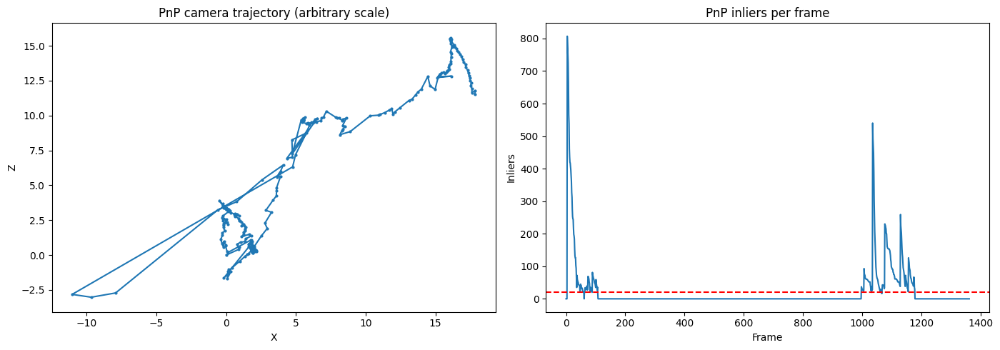

In [61]:
ok_ids=np.array([i for i,T in enumerate(poses) if T is not None],dtype=int)
centers=np.array([poses[i][:3,3] for i in ok_ids])
fig,axs=plt.subplots(1,2,figsize=(14,5))
axs[0].plot(centers[:,0],centers[:,2],'-o',markersize=2)
axs[0].set_title('PnP camera trajectory (arbitrary scale)');axs[0].set_xlabel('X');axs[0].set_ylabel('Z');axs[0].axis('equal')
axs[1].plot([x['frame'] for x in track_log],[x['inliers'] for x in track_log]);axs[1].axhline(MIN_PNP_INLIERS,c='red',ls='--');axs[1].set_title('PnP inliers per frame');axs[1].set_xlabel('Frame');axs[1].set_ylabel('Inliers')
plt.tight_layout();plt.show()
with open(OUTPUT_DIR/'trajectory.csv','w',newline='') as f:
    cw=csv.writer(f);cw.writerow(['frame','source_idx','time_s','x_units','y_units','z_units','status','inliers'])
    for i,fr in enumerate(frames):
        pos=[np.nan]*3 if poses[i] is None else poses[i][:3,3]
        cw.writerow([i,fr['source_idx'],fr['time'],*pos,track_log[i]['status'],track_log[i]['inliers']])
with open(OUTPUT_DIR/'tracking.json','w') as f:json.dump({'tracked':int(sum(t['status']=='tracked' for t in track_log)),'total':len(frames),'init_second_frame':j,'map_points':len(map_xyz),'keyframes':keyframes},f,indent=2)

{
  "monocular_tracking_coverage": 0.20692194403534608,
  "longest_tracked_streak": 111,
  "lost_reasons": {
    "pnp_ransac_rejected": 3,
    "": 1073,
    "too_few_correspondences": 1
  },
  "success_methods": {
    "flow": 273,
    "local": 4,
    "relocalize": 4
  },
  "input_mode": "tum_rgb",
  "frame_step": 1,
  "camera_profile": "tum_fr1",
  "initialization_frame": 3,
  "map_points": 9285,
  "keyframes": 33,
  "tracking_attempts": 1358
}


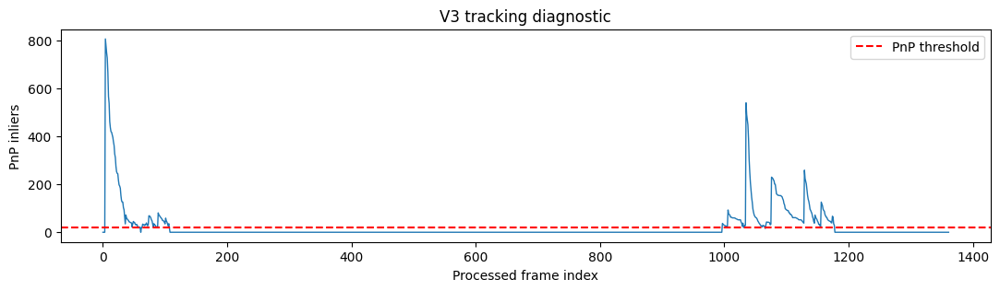

In [62]:
from collections import Counter
statuses=[r['status'] for r in track_log[j+1:]]
reasons=Counter(r.get('reason','') for r in track_log[j+1:] if r['status']=='lost')
methods=Counter(r.get('method','') for r in track_log[j+1:] if r['status']=='tracked')
longest=run=0
for status in statuses:
    run=run+1 if status=='tracked' else 0
    longest=max(longest,run)
coverage=sum(s=='tracked' for s in statuses)/max(len(statuses),1)
summary={'monocular_tracking_coverage':coverage,'longest_tracked_streak':longest,
         'lost_reasons':dict(reasons),'success_methods':dict(methods),
         'input_mode':INPUT_MODE,'frame_step':FRAME_STEP,
         'camera_profile':CAMERA_PROFILE,'initialization_frame':int(j),
         'map_points':int(len(map_xyz)),'keyframes':int(len(keyframes)),
         'tracking_attempts':int(len(statuses))}
print(json.dumps(summary,indent=2))
with open(OUTPUT_DIR/'tracking_diagnostics.json','w') as f:json.dump(summary,f,indent=2)
fig,ax=plt.subplots(figsize=(13,3))
ax.plot([r['frame'] for r in track_log],[r['inliers'] for r in track_log],lw=1)
ax.axhline(MIN_PNP_INLIERS,c='red',ls='--',label='PnP threshold')
ax.set(xlabel='Processed frame index',ylabel='PnP inliers',title='V3 tracking diagnostic');ax.legend();plt.show()


## 6. Sparse map PLY và Plotly interactive viewer

In [63]:
def save_ply(path,xyz,rgb):
    vertices=np.empty(len(xyz),dtype=[('x','f4'),('y','f4'),('z','f4'),('red','u1'),('green','u1'),('blue','u1')])
    for k,name in enumerate(('x','y','z')):vertices[name]=xyz[:,k]
    for k,name in enumerate(('red','green','blue')):vertices[name]=rgb[:,k]
    PlyData([PlyElement.describe(vertices,'vertex')],text=False).write(str(path))
save_ply(OUTPUT_DIR/'sparse_map.ply',map_xyz,map_rgb)

def show_map(xyz,rgb,title='Sparse 3D map + camera trajectory',max_points=18000,html_name='sparse_viewer.html'):
    inds=np.arange(len(xyz))
    if len(inds)>max_points:inds=rng.choice(inds,max_points,replace=False)
    p=xyz[inds];cols=rgb[inds]
    fig=go.Figure()
    fig.add_trace(go.Scatter3d(x=p[:,0],y=p[:,1],z=p[:,2],mode='markers',name='3D landmarks',
        marker={'size':1.8,'color':['rgb(%d,%d,%d)'%tuple(c) for c in cols],'opacity':0.9}))
    # Insert gaps where tracking failed, instead of drawing unobserved continuous path
    px=[np.nan if T is None else T[0,3] for T in poses]
    py=[np.nan if T is None else T[1,3] for T in poses]
    pz=[np.nan if T is None else T[2,3] for T in poses]
    fig.add_trace(go.Scatter3d(x=px,y=py,z=pz,mode='lines',name='Estimated trajectory',line=dict(color='#E76F51',width=5)))
    keys=[k for k in keyframes if poses[k] is not None]
    fig.add_trace(go.Scatter3d(x=[poses[k][0,3] for k in keys],y=[poses[k][1,3] for k in keys],z=[poses[k][2,3] for k in keys],
        mode='markers',name='Keyframes',marker=dict(size=4,color='#22D3EE')))
    fig.update_layout(title=title,scene=dict(aspectmode='data',xaxis_title='X',yaxis_title='Y',zaxis_title='Z'),height=680,margin=dict(l=0,r=0,b=0,t=60))
    fig.write_html(str(OUTPUT_DIR/html_name),include_plotlyjs=True)
    fig.show()
show_map(map_xyz,map_rgb)

## 7. GPU Depth Anything V2 — dense **visualization only**

Depth Anything V2 Small outputs *relative depth*. Here depth is converted to an arbitrary display scale. To avoid falsely presenting the reconstructed geometry as metric, this visualization uses **only one chosen camera frame**; stacking per-frame pseudo-depth without joint scale+pose alignment is geometrically misleading. The sparse map above is the geometry-based multi-frame output.

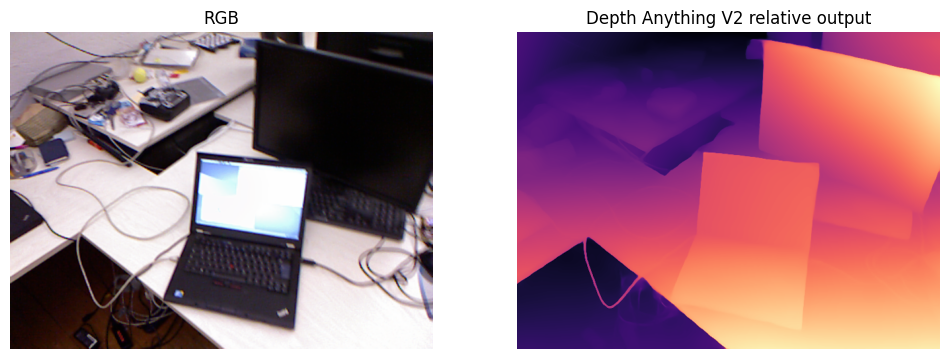

Saved illustrative single-frame pseudo-depth point cloud; not metric geometry.


In [64]:
processor=AutoImageProcessor.from_pretrained(DEPTH_MODEL)
network=AutoModelForDepthEstimation.from_pretrained(DEPTH_MODEL).to(DEVICE).eval()
@torch.inference_mode()
def infer_relative_depth(rgb):
    values=processor(images=Image.fromarray(rgb),return_tensors='pt').to(DEVICE)
    y=network(**values).predicted_depth
    y=torch.nn.functional.interpolate(y.unsqueeze(1),size=rgb.shape[:2],mode='bicubic',align_corners=False).squeeze()
    return y.cpu().numpy().astype(np.float32)
frame_id=keyframes[0]
raw=infer_relative_depth(frames[frame_id]['rgb'])
lo,hi=np.percentile(raw[np.isfinite(raw)],[2,98]);s=np.clip((raw-lo)/(hi-lo+1e-6),0,1)
# visualization pseudo-depth; orientation can vary with depth model output convention
pseudo_z=0.5+4.5*(1-s)
v,u=np.mgrid[0:h:PIXEL_STRIDE,0:w:PIXEL_STRIDE]
z=pseudo_z[::PIXEL_STRIDE,::PIXEL_STRIDE];valid=np.isfinite(z)&(z>0)
camxyz=np.column_stack(((u[valid]-K[0,2])*z[valid]/K[0,0],(v[valid]-K[1,2])*z[valid]/K[1,1],z[valid]))
Twc=poses[frame_id];dense_points=camxyz@Twc[:3,:3].T+Twc[:3,3]
dense_rgb=frames[frame_id]['rgb'][::PIXEL_STRIDE,::PIXEL_STRIDE][valid]
save_ply(OUTPUT_DIR/'single_frame_relative_depth.ply',dense_points,dense_rgb)
fig,ax=plt.subplots(1,2,figsize=(12,5));ax[0].imshow(frames[frame_id]['rgb']);ax[1].imshow(raw,cmap='magma')
ax[0].set_title('RGB');ax[1].set_title('Depth Anything V2 relative output');[x.axis('off') for x in ax];plt.show()
print('Saved illustrative single-frame pseudo-depth point cloud; not metric geometry.')

## 7B. RGB + AI Depth + Interactive single-frame colored 3D viewer

This is **illustrative single-frame reconstruction**, not a metrically accurate or multi-frame fused SLAM map. `Depth Anything V2 Small` predicts **relative depth**. The display-only range below cannot be interpreted as meters. Plotly offers rotate / zoom / toggle. This section can run even when PnP tracking is poor because it does not require camera pose.

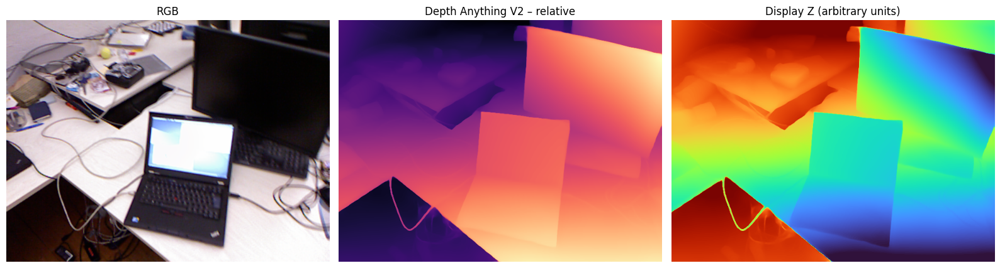

Single frame predicted point cloud: 34240 points


In [65]:
# Visualize the same selected frame with its predicted depth and 3D point cloud.
# Use frame_id from the existing AI Depth cell (cell above).
import plotly.graph_objects as go
from IPython.display import display

DISPLAY_DEPTH_MIN, DISPLAY_DEPTH_MAX = 0.5, 5.0  # arbitrary *visual* units
VIEW_STRIDE = 3
VIEW_MAX_POINTS = 35000

finite = np.isfinite(raw)
assert finite.any(), 'Depth model returned no finite pixels'
p2, p98 = np.percentile(raw[finite], [2, 98])
rel = np.clip((raw - p2) / max(p98-p2, 1e-6), 0, 1)
# DAv2 relative prediction is normally larger for nearer surfaces (inverse-depth-like).
# Convert to illustrative camera Z with farther surfaces assigned larger Z.
z_display = DISPLAY_DEPTH_MAX - rel * (DISPLAY_DEPTH_MAX-DISPLAY_DEPTH_MIN)

def backproject_rgb(rgb, depth_z, K, stride=3, low=0.01, high=np.inf):
    height, width = depth_z.shape
    vv, uu = np.mgrid[0:height:stride, 0:width:stride]
    zz = depth_z[::stride, ::stride]
    colors = rgb[::stride, ::stride]
    valid = np.isfinite(zz) & (zz > low) & (zz < high)
    zz=zz[valid].astype(np.float32)
    xx=(uu[valid]-K[0,2])*zz/K[0,0]
    yy=(vv[valid]-K[1,2])*zz/K[1,1]
    return np.column_stack((xx,yy,zz)),colors[valid]

pred_xyz, pred_rgb=backproject_rgb(frames[frame_id]['rgb'],z_display,K,VIEW_STRIDE)
if len(pred_xyz)>VIEW_MAX_POINTS:
    chosen=rng.choice(len(pred_xyz),VIEW_MAX_POINTS,replace=False)
    pred_xyz,pred_rgb=pred_xyz[chosen],pred_rgb[chosen]

plt.figure(figsize=(16,5))
plt.subplot(1,3,1);plt.imshow(frames[frame_id]['rgb']);plt.title('RGB');plt.axis('off')
plt.subplot(1,3,2);plt.imshow(raw,cmap='magma');plt.title('Depth Anything V2 – relative');plt.axis('off')
plt.subplot(1,3,3);plt.imshow(z_display,cmap='turbo');plt.title('Display Z (arbitrary units)');plt.axis('off')
plt.tight_layout();plt.show()

def scatter_cloud(pts,cols,name,size=1.5,visible=True):
    return go.Scatter3d(x=pts[:,0],y=pts[:,1],z=pts[:,2],mode='markers',name=name,visible=visible,
        marker=dict(size=size,color=['rgb({},{},{})'.format(*map(int,c)) for c in cols],opacity=0.95))

fig=go.Figure([scatter_cloud(pred_xyz,pred_rgb,'AI Depth – one RGB frame')])
fig.update_layout(title='AI Depth single frame – illustrative colored point cloud (not meters)',
    scene=dict(xaxis_title='X',yaxis_title='Y',zaxis_title='Z',aspectmode='data',
               yaxis=dict(autorange='reversed')),
    height=720,margin=dict(l=0,r=0,t=60,b=0))
fig.show()
fig.write_html(str(OUTPUT_DIR/'predicted_depth_single_frame_3d.html'),include_plotlyjs=True)
save_ply(OUTPUT_DIR/'predicted_depth_single_frame_3d.ply',pred_xyz,pred_rgb)
print('Single frame predicted point cloud:',len(pred_xyz),'points')

## 7C. Optional TUM RGB-D validation: timestamp-synchronized sensor depth versus predicted depth

For `freiburg1_room`, the original dataset contains RGB and sensor depth. Match their **timestamps**, not filename order. Use sensor depth with Freiburg1 scale **5000 units per meter**. If no TUM dataset is found, the section skips comparison. The predicted depth is *relative*: we fit an affine transformation **only for diagnostic comparison to the sensor**. That fit uses ground truth and must **not** be interpreted as a deployable monocular metric-depth model.

The evaluation below uses the same original RGB file as the selected video frame in Section 7B (assuming the MP4 was created in cell 5 without dropping/reordering images).

timestamp-matched RGB-depth pairs: 1362
Diagnostic affine-fit MAE (m): 0.0862 fit slope: -0.21592


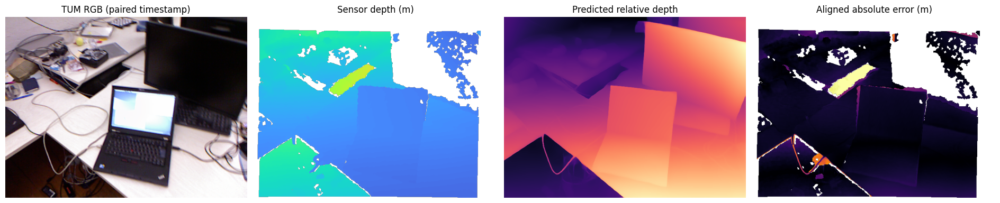

In [66]:
from pathlib import Path
from scipy.ndimage import map_coordinates

# Existing DATASET_PATH from the download cell, or override manually.
TUM_ROOT=Path(globals().get('DATASET_PATH','/kaggle/working/data/rgbd_dataset_freiburg1_room'))
TUM_ROOT=TUM_ROOT if (TUM_ROOT/'rgb.txt').exists() else None

def read_tum_index(path):
    items=[]
    with open(path) as f:
        for line in f:
            if not line.strip() or line.startswith('#'):continue
            parts=line.split()
            if len(parts)>=2:items.append((float(parts[0]),parts[1]))
    return items

def pair_tum_images(root,max_dt=.02):
    rgb_i=read_tum_index(root/'rgb.txt'); dep_i=read_tum_index(root/'depth.txt')
    td=np.array([x[0] for x in dep_i]); pairs=[]
    for ts,rgb_rel in rgb_i:
        nearest=int(np.argmin(np.abs(td-ts)))
        if abs(td[nearest]-ts)<=max_dt:pairs.append((ts,root/rgb_rel,root/dep_i[nearest][1]))
    return pairs

if TUM_ROOT is None:
    print('No TUM RGB-D folder found. Sensor depth comparison skipped.')
else:
    paired=pair_tum_images(TUM_ROOT)
    print('timestamp-matched RGB-depth pairs:',len(paired))
    assert paired,'No RGB/depth pairs; verify paths and timestamp tolerance.'
    # Explicitly choose a dataset pair; do not assume it matches the processed MP4 frame_id.
    # Match the RGB image corresponding to the MP4 source frame rather than a separate scene.
    # The video was built from sorted original PNG images in cell 5.
    src_i = frames[frame_id]['source_idx']
    original_rgb_files = sorted((TUM_ROOT/'rgb').glob('*.png'))
    if 0 <= src_i < len(original_rgb_files):
        chosen_name = original_rgb_files[src_i].name
        pair_idx = next((k for k,p in enumerate(paired) if p[1].name == chosen_name), None)
    else:
        pair_idx = None
    if pair_idx is None:
        # Fall back to closest timestamp parsed from video source image if possible.
        pair_idx = min(src_i, len(paired)-1)
        print('WARNING: exact image timestamp association not found; verify selected RGB images.')
    ts,rgb_path,depth_path=paired[pair_idx]
    tum_rgb=cv2.cvtColor(cv2.imread(str(rgb_path)),cv2.COLOR_BGR2RGB)
    sensor_raw=cv2.imread(str(depth_path),cv2.IMREAD_UNCHANGED)
    assert sensor_raw is not None and sensor_raw.dtype==np.uint16
    sensor_z=sensor_raw.astype(np.float32)/5000.0
    pred_tum=infer_relative_depth(tum_rgb)
    assert pred_tum.shape==sensor_z.shape
    valid=(sensor_z>.2)&(sensor_z<5)&np.isfinite(pred_tum)
    # Fit predicted relative output -> metric Z, only for dataset evaluation.
    rel_x=pred_tum[valid].astype(np.float64); target=sensor_z[valid].astype(np.float64)
    if len(target)<500:
        print('Not enough valid depth pixels for comparison')
    else:
        sample=np.linspace(0,len(target)-1,min(50000,len(target)),dtype=int)
        coeff=np.linalg.lstsq(np.column_stack((rel_x[sample],np.ones(len(sample)))),target[sample],rcond=None)[0]
        aligned_z=coeff[0]*pred_tum+coeff[1]
        # Negative slope expected for inverse-depth-like predictions; fit is only a diagnostic.
        fit_valid=valid & (aligned_z>0)
        mae=float(np.mean(np.abs(aligned_z[fit_valid]-sensor_z[fit_valid]))) if fit_valid.any() else float('nan')
        print('Diagnostic affine-fit MAE (m):',round(mae,4),'fit slope:',round(float(coeff[0]),5))
        fig,axs=plt.subplots(1,4,figsize=(19,5))
        axs[0].imshow(tum_rgb);axs[0].set_title('TUM RGB (paired timestamp)')
        axs[1].imshow(np.ma.masked_where(~valid,sensor_z),cmap='turbo',vmin=.2,vmax=5);axs[1].set_title('Sensor depth (m)')
        axs[2].imshow(pred_tum,cmap='magma');axs[2].set_title('Predicted relative depth')
        axs[3].imshow(np.ma.masked_where(~fit_valid,np.abs(aligned_z-sensor_z)),cmap='inferno',vmin=0,vmax=1);axs[3].set_title('Aligned absolute error (m)')
        for ax in axs:ax.axis('off')
        plt.tight_layout();plt.show()


## 7D. Optional actual sensor-depth colored 3D viewer

This reconstructs **one TUM RGB-D frame** from actual depth. It is a useful sanity check for the camera intrinsics and backprojection. It does not magically produce an entire room or solve SLAM.

In [67]:
if TUM_ROOT is not None and 'tum_rgb' in globals() and 'sensor_z' in globals():
    # Original Freiburg1 RGB at 640×480. Use the camera matrix for the *original* sensor resolution.
    K_tum=np.array([[517.3,0,318.6],[0,516.5,255.3],[0,0,1]],dtype=float)
    xyz_tum,color_tum=backproject_rgb(tum_rgb,sensor_z,K_tum,stride=3,low=.2,high=5.)
    if len(xyz_tum)>VIEW_MAX_POINTS:
        chosen=rng.choice(len(xyz_tum),VIEW_MAX_POINTS,replace=False)
        xyz_tum,color_tum=xyz_tum[chosen],color_tum[chosen]
    fig=go.Figure([scatter_cloud(xyz_tum,color_tum,'TUM measured depth, one frame')])
    fig.update_layout(title='TUM single-frame RGB-D – sensor depth (meters)',
        height=720,scene=dict(aspectmode='data',xaxis_title='X (m)',yaxis_title='Y (m)',zaxis_title='Z (m)',yaxis=dict(autorange='reversed')))
    fig.show()
    fig.write_html(str(OUTPUT_DIR/'tum_sensor_single_frame_3d.html'),include_plotlyjs=True)
    save_ply(OUTPUT_DIR/'tum_sensor_single_frame_3d.ply',xyz_tum,color_tum)
    print('Sensor-depth point cloud:',len(xyz_tum),'points')
else:
    print('Skipped: no paired TUM RGB-D frame available')

Sensor-depth point cloud: 24488 points


## 8. Metrics, limitations và nâng cấp tiếp

**Cần làm trước khi gọi đây là SLAM đầy đủ:** (1) 2D–3D persistent landmark observations across keyframes, (2) robust local bundle adjustment, (3) place recognition + verified loop closure, (4) pose graph optimization, (5) recover tracking after failure, (6) for metric scale use stereo/RGB-D/IMU or known scene dimension. Nếu dùng video MP4 thường, tuyệt đối không gắn nhãn tọa độ `m`.

**TUM `fr1_room` / `fr1_desk`:** có thể làm thêm cell associate timestamps và align trajectory sang ground truth bằng Sim(3) để báo cáo ATE monocular; không làm điều này trên video không có ground truth.


In [68]:
print('Output folder:',OUTPUT_DIR)
for f in OUTPUT_DIR.iterdir():print(f.name,round(f.stat().st_size/1024,1),'KB')
print('NOTE: No claim of full loop closure or metric-scale recovery.')

Output folder: /kaggle/working/visual_slam_upgrade
same_frame_sensor_depth.ply 202.6 KB
sparse_viewer.html 5167.7 KB
same_frame_ai_affine_depth.ply 202.6 KB
tracking_diagnostics.json 0.4 KB
tum_sensor_single_frame_3d.html 6285.5 KB
predicted_depth_single_frame_3d.ply 501.7 KB
tum_sensor_single_frame_3d.ply 358.9 KB
same_frame_depth_comparison.html 6519.0 KB
single_frame_relative_depth.ply 93.2 KB
predicted_depth_single_frame_3d.html 6947.3 KB
sparse_map.ply 136.2 KB
tracking.json 0.4 KB
trajectory.csv 75.1 KB
rgbd_trajectory_metrics.json 0.1 KB
NOTE: No claim of full loop closure or metric-scale recovery.


## 9A. RGB-D baseline: frame-to-frame PnP using **measured TUM depth**

This section is **optional** and only runs when `TUM_ROOT` points to the downloaded dataset. Unlike the monocular baseline above, it uses depth measured by the RGB-D sensor **as input to tracking**, not ground-truth camera poses. For frame k, detect/match ORB keypoints between k and k+1; back-project points from k using its depth; estimate `T_(k+1),k` with PnP-RANSAC; accumulate poses. A failed step remains missing. This is an RGB-D visual-odometry baseline, **not full SLAM** (no loop closure or bundle adjustment).

It is deliberately independent of the fragile monocular sparse-map tracker so you can tell whether failures are caused by monocular triangulation/landmark reuse.

In [69]:
from scipy.spatial.transform import Rotation

RGBD_MAX_PAIRS = 400   # start small on Kaggle; raise after verifying results
RGBD_STEP = 2         # 1 = adjacent dataset frames (most reliable), 2 = every other
RGBD_MIN_INLIERS = 25
RGBD_MAX_DEPTH_M = 5.0
RGBD_MAX_REPROJ_PX = 3.0
K_RGBD = np.array([[517.3,0,318.6],[0,516.5,255.3],[0,0,1]], dtype=np.float64)

def rgbd_pair_pose(rgb_a, depth_a, rgb_b, K):
    gray_a = cv2.cvtColor(rgb_a,cv2.COLOR_RGB2GRAY)
    gray_b = cv2.cvtColor(rgb_b,cv2.COLOR_RGB2GRAY)
    kp_a,desc_a = orb.detectAndCompute(gray_a,None)
    kp_b,desc_b = orb.detectAndCompute(gray_b,None)
    if desc_a is None or desc_b is None or len(desc_a)<2 or len(desc_b)<2:
        return None,0,0
    matches = matcher.knnMatch(desc_a,desc_b,k=2)
    matches = [m for row in matches if len(row)==2 for m,q in [row] if m.distance < 0.75*q.distance]
    # Remove duplicate train indices so each target pixel has at most one source point
    unique = {}
    for m in sorted(matches,key=lambda m:m.distance):
        unique.setdefault(m.trainIdx,m)
    objects, pixels = [], []
    H,W=depth_a.shape
    for m in unique.values():
        u,v=kp_a[m.queryIdx].pt
        ui,vi=int(round(u)),int(round(v))
        if not (0<=ui<W and 0<=vi<H):continue
        z=float(depth_a[vi,ui])
        if not (0.2<z<RGBD_MAX_DEPTH_M):continue
        objects.append([(u-K[0,2])*z/K[0,0],(v-K[1,2])*z/K[1,1],z])
        pixels.append(kp_b[m.trainIdx].pt)
    count=len(objects)
    if count < RGBD_MIN_INLIERS:return None,count,0
    obj=np.ascontiguousarray(objects,np.float64)
    pix=np.ascontiguousarray(pixels,np.float64)
    ok,rvec,tvec,ids=cv2.solvePnPRansac(obj,pix,K,None,iterationsCount=250,
        reprojectionError=RGBD_MAX_REPROJ_PX,confidence=0.999,flags=cv2.SOLVEPNP_EPNP)
    nin=0 if ids is None else len(ids)
    if not ok or nin<RGBD_MIN_INLIERS:return None,count,nin
    rvec,tvec=cv2.solvePnPRefineLM(obj[ids.ravel()],pix[ids.ravel()],K,None,rvec,tvec)
    R,_=cv2.Rodrigues(rvec)
    # PnP maps points in camera k to camera k+1; inverse maps k+1 into k.
    return np.linalg.inv(transform(R,tvec)),count,nin

def read_rgbd_pair(pair):
    ts, rgb_path, dep_path=pair
    bgr=cv2.imread(str(rgb_path),cv2.IMREAD_COLOR)
    dep=cv2.imread(str(dep_path),cv2.IMREAD_UNCHANGED)
    if bgr is None or dep is None:raise FileNotFoundError((rgb_path,dep_path))
    rgb=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
    depth=dep.astype(np.float32)/5000.0
    return rgb,depth

rgbd_ids=[];rgbd_poses={};rgbd_log=[]
if TUM_ROOT is None:
    print('Skip RGB-D tracking: TUM dataset not present.')
else:
    rgbd_ids=list(range(0,min(len(paired),RGBD_MAX_PAIRS*RGBD_STEP),RGBD_STEP))
    assert len(rgbd_ids)>2, 'Not enough matched RGB-D pairs'
    rgbd_poses[rgbd_ids[0]]=np.eye(4)
    prev_rgb,prev_dep=read_rgbd_pair(paired[rgbd_ids[0]])
    for prev_id,cur_id in zip(rgbd_ids[:-1],rgbd_ids[1:]):
        cur_rgb,cur_dep=read_rgbd_pair(paired[cur_id])
        T_step,nmatch,nin=rgbd_pair_pose(prev_rgb,prev_dep,cur_rgb,K_RGBD)
        if T_step is not None and prev_id in rgbd_poses:
            rgbd_poses[cur_id]=rgbd_poses[prev_id]@T_step
            status='tracked'
        else:
            status='lost'
        rgbd_log.append({'frame':cur_id,'timestamp':paired[cur_id][0],
                         'matches':nmatch,'inliers':nin,'status':status})
        prev_rgb,prev_dep=cur_rgb,cur_dep
    print('RGB-D tracking:',len(rgbd_poses),'/',len(rgbd_ids),'poses; failures:',
          sum(r['status']=='lost' for r in rgbd_log))
    print('NOTE: after a failure this minimal baseline does not relocalize; later poses remain missing.')


RGB-D tracking: 400 / 400 poses; failures: 0
NOTE: after a failure this minimal baseline does not relocalize; later poses remain missing.


## 9B. Evaluate estimated RGB-D trajectory against TUM ground truth

Ground truth is used **only here for evaluation**. Timestamps are paired within 20 ms; trajectories are aligned by rigid SE(3) with **no scale fit** (sensor depth provides metric scale). Errors are diagnostic and include the number of valid compared poses, because low tracking coverage can hide failure.

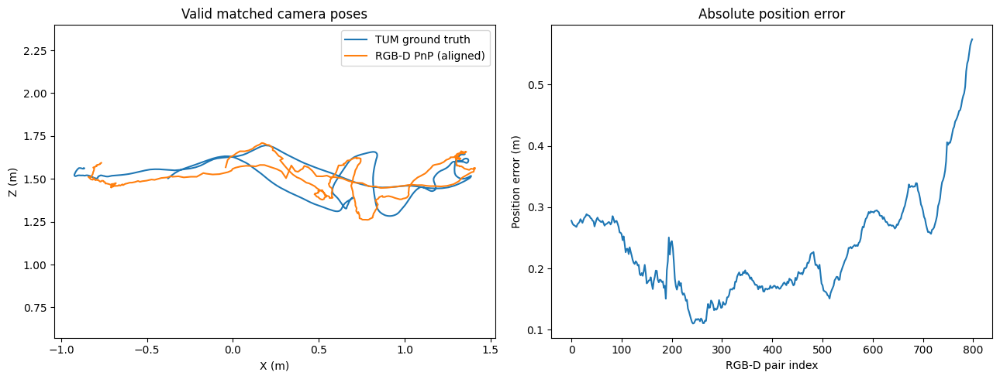

RGB-D ATE RMSE (SE3-aligned, no scale fit): 0.2506 m | compared 400/400 selected frames


In [70]:
def read_tum_groundtruth(path):
    stamps=[];centers=[]
    with open(path) as f:
        for line in f:
            if not line.strip() or line.startswith('#'):continue
            cols=line.split()
            if len(cols)<8:continue
            stamps.append(float(cols[0]));centers.append([float(x) for x in cols[1:4]])
    return np.asarray(stamps),np.asarray(centers)

def rigid_align(A,B):
    # Fit B ~= A @ R.T + t using matched 3D positions, with NO scale correction.
    ma=A.mean(axis=0);mb=B.mean(axis=0)
    U,S,Vt=np.linalg.svd((A-ma).T@(B-mb))
    R=Vt.T@np.diag([1,1,np.linalg.det(Vt.T@U.T)])@U.T
    t=mb-R@ma
    return R,t

if TUM_ROOT is not None and rgbd_poses and (TUM_ROOT/'groundtruth.txt').exists():
    ts_gt, xyz_gt=read_tum_groundtruth(TUM_ROOT/'groundtruth.txt')
    pred=[];true=[];taken=[]
    for idx,T in sorted(rgbd_poses.items()):
        ts=paired[idx][0]
        k=int(np.argmin(np.abs(ts_gt-ts)))
        if abs(ts-ts_gt[k])<=.02:
            pred.append(T[:3,3]);true.append(xyz_gt[k]);taken.append(idx)
    if len(pred)>=4:
        pred=np.asarray(pred);true=np.asarray(true)
        R,t=rigid_align(pred,true)
        aligned=pred@R.T+t
        residual=np.linalg.norm(aligned-true,axis=1)
        ate=float(np.sqrt(np.mean(residual**2)))
        fig,axs=plt.subplots(1,2,figsize=(13,5))
        axs[0].plot(true[:,0],true[:,2],label='TUM ground truth')
        axs[0].plot(aligned[:,0],aligned[:,2],label='RGB-D PnP (aligned)')
        axs[0].axis('equal');axs[0].set(xlabel='X (m)',ylabel='Z (m)',title='Valid matched camera poses')
        axs[0].legend()
        axs[1].plot(taken,residual);axs[1].set(xlabel='RGB-D pair index',ylabel='Position error (m)',title='Absolute position error')
        plt.tight_layout();plt.show()
        print(f'RGB-D ATE RMSE (SE3-aligned, no scale fit): {ate:.4f} m | compared {len(taken)}/{len(rgbd_ids)} selected frames')
        with open(OUTPUT_DIR/'rgbd_trajectory_metrics.json','w') as f:
            json.dump({'ate_rmse_m':ate,'compared_frames':len(taken),
                       'sampled_frames':len(rgbd_ids),'tracking_poses':len(rgbd_poses)},f,indent=2)
    else:print('Too few time-matched poses to compute ATE')


## 9C. Same-frame predicted vs measured depth + identical camera views

The output below uses the **same** RGB image, camera matrix, depth-validity mask and Z range on both sides. A least-squares affine fit is a *diagnostic* for relative depth, NOT an independent metric-depth evaluation. Render cloud shapes with fixed axis ranges to make the difference obvious.

On-frame affine-fit diagnostic: RMSE=0.170m AbsRel=0.066; NOT independent model performance


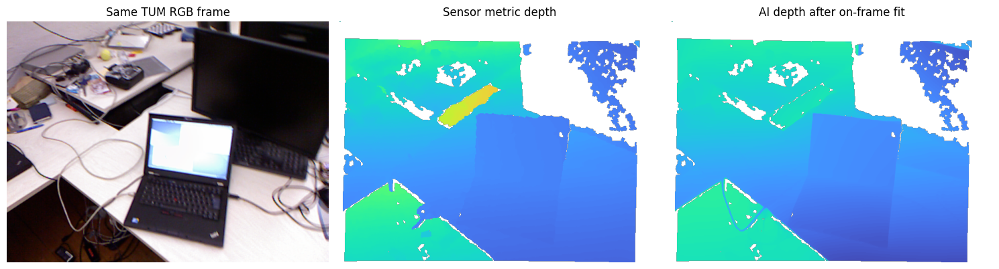

In [71]:
if TUM_ROOT is None:
    print('Skip: no TUM sensor depth available')
else:
    # Use the exact TUM paired image already selected in section 7C.
    assert tum_rgb.shape[:2]==sensor_z.shape
    pred_same=infer_relative_depth(tum_rgb)
    valid=(np.isfinite(pred_same)&np.isfinite(sensor_z)&(sensor_z>.3)&(sensor_z<4.5))
    x=pred_same[valid].astype(float);y=sensor_z[valid].astype(float)
    assert len(x)>1000
    rng_fit=np.random.default_rng(12)
    fit_idx=rng_fit.choice(len(x),size=min(len(x),30000),replace=False)
    a,b=np.linalg.lstsq(np.c_[x[fit_idx],np.ones(len(fit_idx))],y[fit_idx],rcond=None)[0]
    aligned=a*pred_same+b
    aligned_valid=valid&(aligned>.3)&(aligned<4.5)
    eval_mask=aligned_valid
    rmse=float(np.sqrt(np.mean((aligned[eval_mask]-sensor_z[eval_mask])**2)))
    absrel=float(np.mean(np.abs(aligned[eval_mask]-sensor_z[eval_mask])/sensor_z[eval_mask]))
    print(f'On-frame affine-fit diagnostic: RMSE={rmse:.3f}m AbsRel={absrel:.3f}; NOT independent model performance')
    p_xyz,p_col=backproject_rgb(tum_rgb,np.where(aligned_valid,aligned,0),K_RGBD,stride=4,low=.3,high=4.5)
    s_xyz,s_col=backproject_rgb(tum_rgb,np.where(valid,sensor_z,0),K_RGBD,stride=4,low=.3,high=4.5)
    fig,axs=plt.subplots(1,3,figsize=(15,4))
    axs[0].imshow(tum_rgb);axs[0].set_title('Same TUM RGB frame')
    axs[1].imshow(np.ma.masked_where(~valid,sensor_z),vmin=.3,vmax=4.5,cmap='turbo');axs[1].set_title('Sensor metric depth')
    axs[2].imshow(np.ma.masked_where(~aligned_valid,aligned),vmin=.3,vmax=4.5,cmap='turbo');axs[2].set_title('AI depth after on-frame fit')
    for ax in axs:ax.axis('off')
    plt.tight_layout();plt.show()
    fig3=go.Figure()
    fig3.add_trace(scatter_cloud(p_xyz,p_col,'AI aligned depth',size=1.5))
    fig3.add_trace(scatter_cloud(s_xyz,s_col,'Sensor depth',size=1.5,visible='legendonly'))
    fig3.update_layout(title='Same-frame 3D comparison (toggle traces in legend)',height=750,
      scene=dict(aspectmode='data',xaxis=dict(title='X (m)',range=[-3,3]),
         yaxis=dict(title='Y (m)',range=[2.5,-2.5]),
         zaxis=dict(title='Z (m)',range=[0,4.5])))
    fig3.show()
    fig3.write_html(str(OUTPUT_DIR/'same_frame_depth_comparison.html'),include_plotlyjs=True)
    save_ply(OUTPUT_DIR/'same_frame_ai_affine_depth.ply',p_xyz,p_col)
    save_ply(OUTPUT_DIR/'same_frame_sensor_depth.ply',s_xyz,s_col)


In [72]:
import shutil

shutil.make_archive(
    "/kaggle/working/visual_slam_upgrade",
    "zip",
    root_dir="/kaggle/working",
    base_dir="visual_slam_upgrade"
)

print("✅ Đã tạo: /kaggle/working/visual_slam_upgrade.zip")

✅ Đã tạo: /kaggle/working/visual_slam_upgrade.zip
